# Outlier filtering for labeled diagnostic data

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import umap.umap_ as umap
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import hdbscan
from dotenv import load_dotenv

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

X_path = os.getenv("LABELED_DIAGNOSTIC_X_CSV_PATH")
y_path = os.getenv("LABELED_DIAGNOSTIC_Y_TSV_PATH")
output_dir = os.getenv("OUTPUT_DIR")
random_seed = int(os.getenv("RANDOM_SEED"))


print("Configuration:")
print(f"X path: {X_path}")
print(f"y path: {y_path}")
print(f"Output dir: {output_dir}")
print(f"Random seed: {random_seed}")

# Make sure output dir exists
os.makedirs(output_dir, exist_ok=True)

Configuration:
X path: /home/mariya/Data/pallas/nf-core-gexml-output/transpose/transposed.csv
y path: /home/mariya/Data/pallas/nf-core-gexml-output/class/subtypes.tsv
Output dir: /home/mariya/Data/pallas/training
Random seed: 42


In [4]:
import pandas as pd
import numpy as np
import umap
import hdbscan
from sklearn.preprocessing import OneHotEncoder

def create_umap(X, y):
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(X)

    reducer = umap.UMAP(n_neighbors=15,
                    min_dist=0.1,
                    n_components=2,
                    random_state=random_seed)

    embedding_umap = reducer.fit_transform(scaled_data)

    umap_df = pd.DataFrame(embedding_umap, columns=['UMAP1', 'UMAP2'], index=X.index)
    umap_df['label'] = y.loc[umap_df.index]
    return umap_df

def show_umap(umap_df, title, legend_title='Subtype'):
    # Generate a custom palette with enough colors for all categories using 'tab20'
    # Pick a palette that can handle many classes
    num_categories = umap_df['label'].nunique()
    custom_palette = sns.color_palette("husl", n_colors=num_categories)

    # Plot UMAP
    plt.figure(figsize=(10,10))
    sns.scatterplot(x='UMAP1',
                    y='UMAP2',
                    hue='label',
                    data=umap_df,
                    palette=custom_palette,
                    s=50,
                    alpha=0.8)

    plt.title(title, fontsize=18)
    plt.legend(
        title=legend_title,
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        borderaxespad=0,
        prop={'size': 8}
    )
    plt.tight_layout()
    plt.show()

# Create new col "disease" that sets B-ALL, T-ALL, AML or Non-leukemic
def map_disease(subtype):
    if "B-ALL" in subtype:
        return "B-ALL"
    elif "T-ALL" in subtype:
        return "T-ALL"
    elif "AML" in subtype:
        return "AML"
    else:
        return "Non-leukemic"

def umap_hdbscan_with_text(X_numeric, cat_labels, other_metadata=None,
                           n_neighbors=15, min_dist=0.1,
                           min_cluster_size=15, min_samples=5, random_state=random_seed,
                           outlier_threshold_percentile=95):
    """
    Combine numeric features with categorical labels, run UMAP + HDBSCAN,
    return results with clusters, outlier flags, and preserve original X index.
    """
    # --- Step 1: Encode categorical labels ---
    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    X_cat = encoder.fit_transform(cat_labels.values.reshape(-1, 1))

    # --- Step 2: Combine numeric + categorical features ---
    if isinstance(X_numeric, pd.DataFrame):
        X_index = X_numeric.index  # keep original index
        X_numeric_array = X_numeric.values
    else:
        X_index = pd.RangeIndex(len(X_numeric))  # fallback if numpy array
        X_numeric_array = X_numeric

    X_full = np.hstack([X_numeric_array, X_cat])

    # --- Step 3: UMAP embedding ---
    reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist,
                        random_state=random_state)
    X_umap = reducer.fit_transform(X_full)

    # --- Step 4: HDBSCAN clustering ---
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size,
                                min_samples=min_samples).fit(X_umap)
    labels = clusterer.labels_
    outliers = labels == -1

    # --- Step 5: Assemble results, preserve index ---
    results = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"], index=X_index)
    results["Cluster"] = labels
    results["Outlier"] = outliers
    results["Category"] = cat_labels.values

    results["OutlierScore"] = clusterer.outlier_scores_
    threshold = np.percentile(results["OutlierScore"], outlier_threshold_percentile)
    results["StrictOutlier"] = results["OutlierScore"] > threshold

    if other_metadata is not None:
        other_metadata = other_metadata.set_index(X_index)
        results = pd.concat([results, other_metadata], axis=1)

    return results

def plot_class_distribution(y_series, title):
    counts = y_series.value_counts().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    # Change this so the bar also displays the count value on top of each bar
    ax = counts.plot(kind='bar')
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.xticks(rotation=90)
    for p in ax.patches:
        ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom')
    plt.show()

In [5]:
X = pd.read_csv(X_path, header=0, index_col=0)
target = pd.read_csv(y_path, header=0, index_col=0, sep="\t")
y = target['class']
# Assert that they are the same length
assert len(X) == len(y), f"X and y have different lengths: {len(X)} vs {len(y)}"

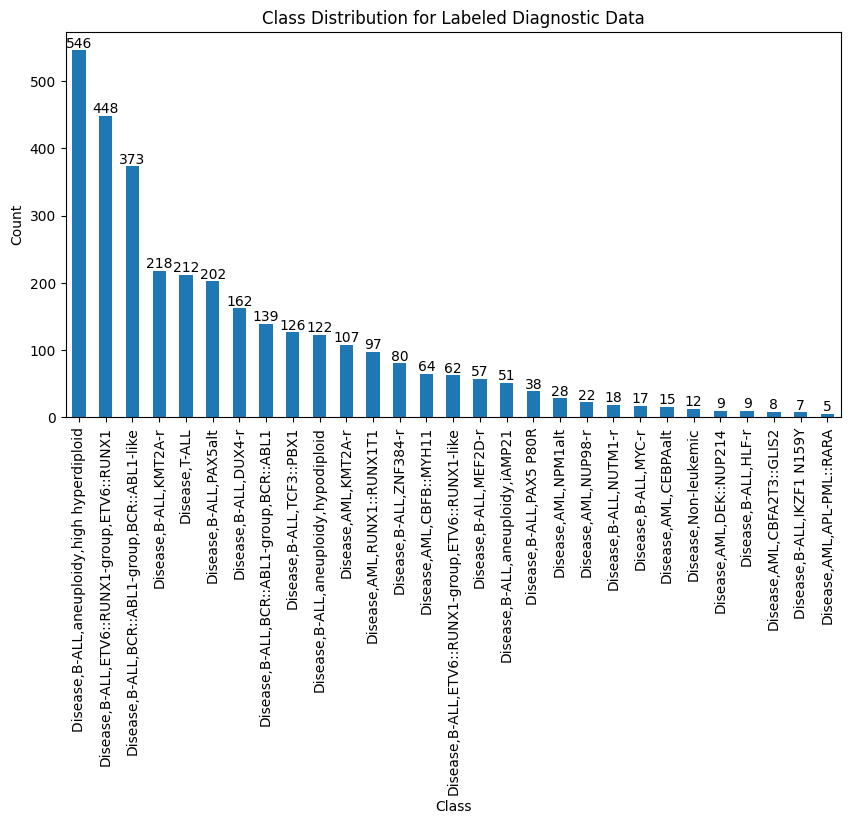

In [6]:
plot_class_distribution(y, "Class Distribution for Labeled Diagnostic Data")

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


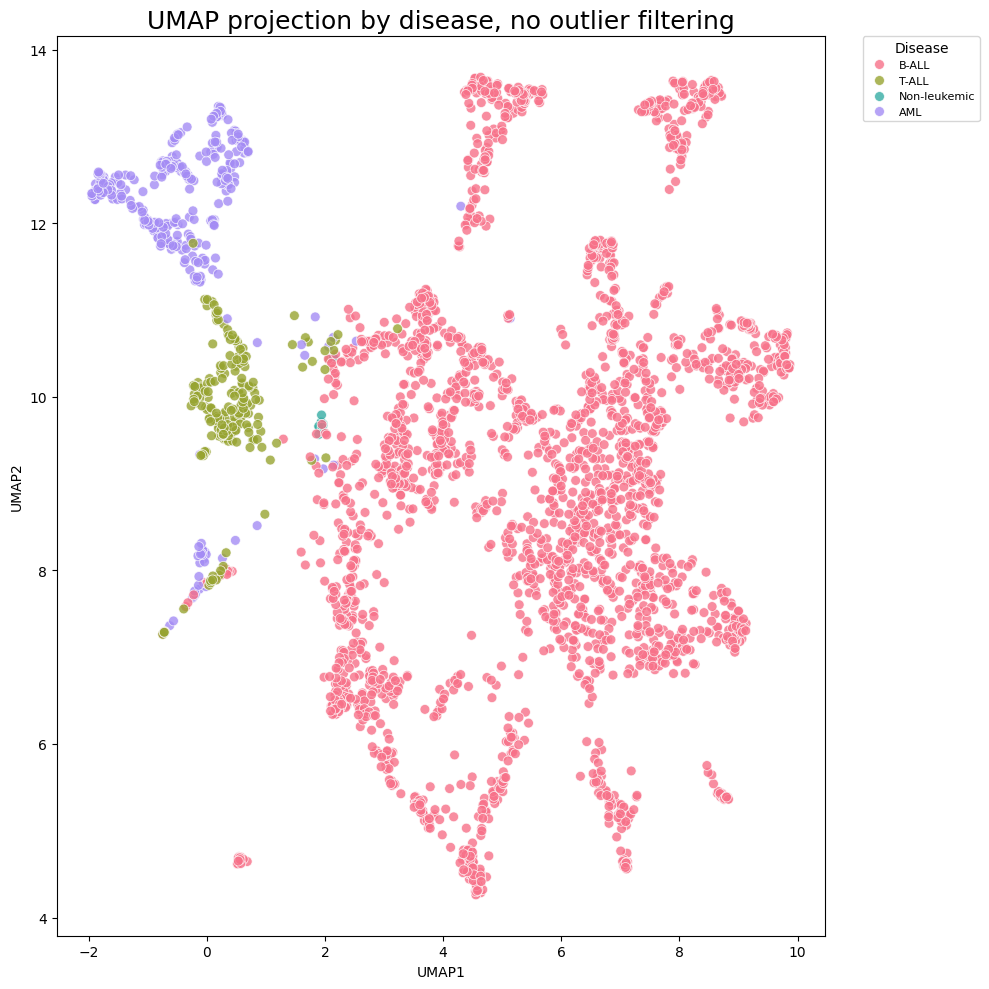

In [7]:
target['disease'] = target['class'].apply(map_disease)
disease = target['disease']
umap_df = create_umap(X, disease)
show_umap(umap_df, "UMAP projection by disease, no outlier filtering", "Disease")

/tmp/ipykernel_24283/3825643116.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  X_b_all = X[disease == "B-ALL"]
/tmp/ipykernel_24283/3825643116.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  X_aml = X[disease == "AML"]
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


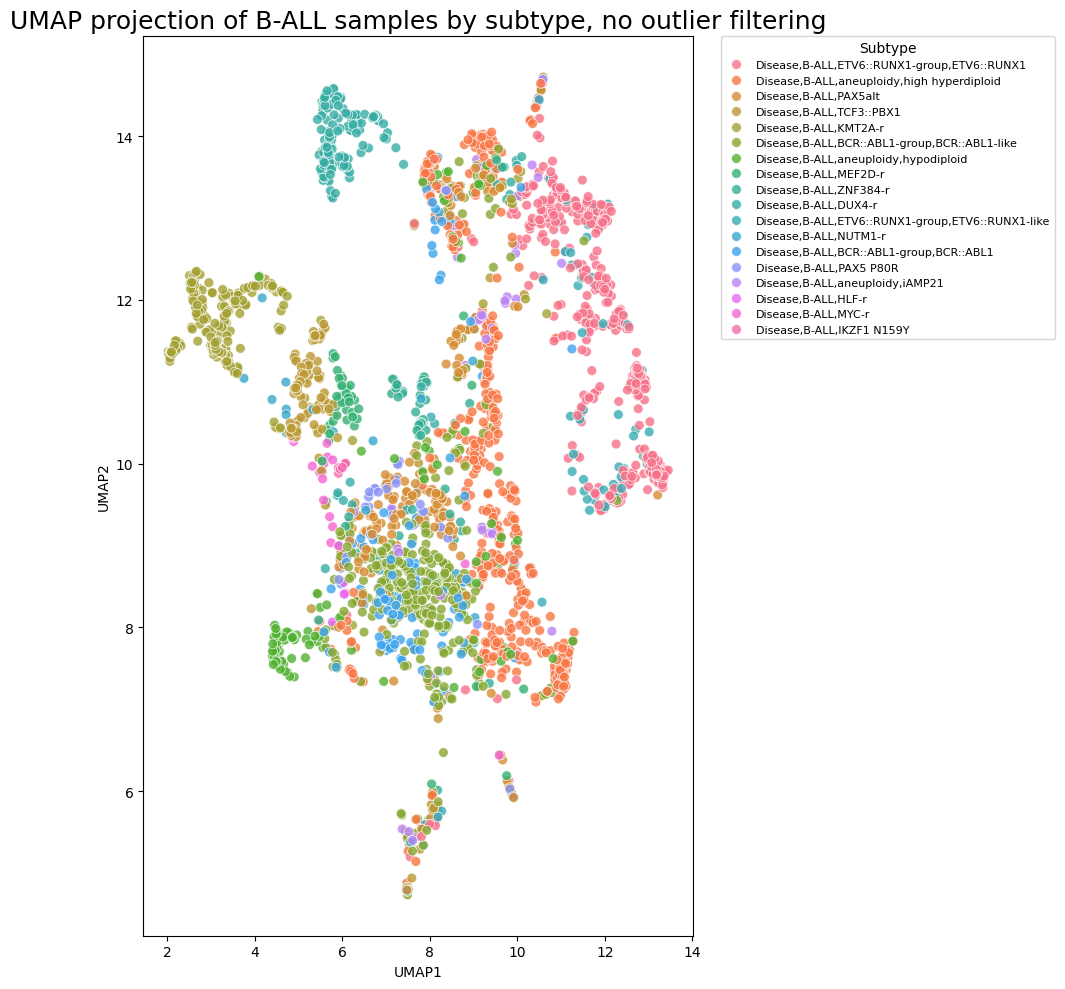

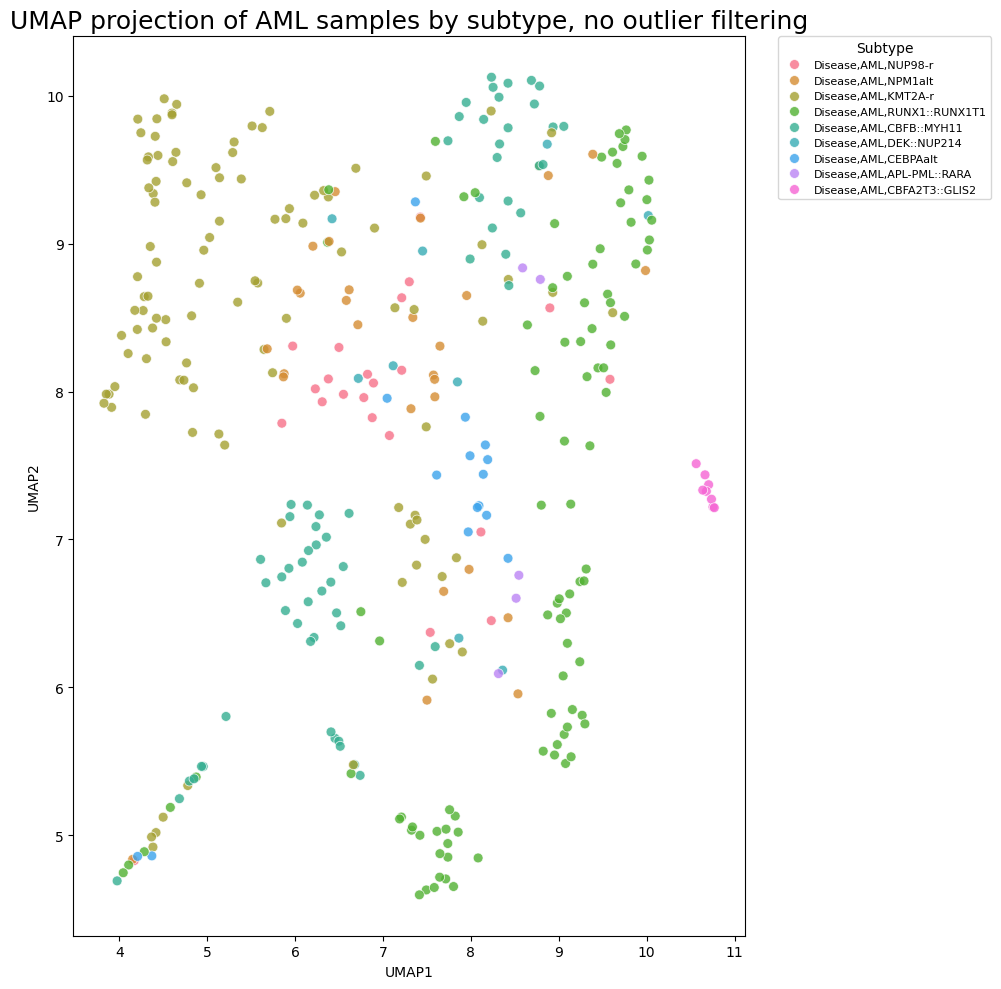

In [8]:
# Split x and y by disease
X_b_all = X[disease == "B-ALL"]
y_b_all = y[disease == "B-ALL"]
X_aml = X[disease == "AML"]
y_aml = y[disease == "AML"]

umap_df_b_all = create_umap(X_b_all, y_b_all)
umap_df_aml = create_umap(X_aml, y_aml)

show_umap(umap_df_b_all, "UMAP projection of B-ALL samples by subtype, no outlier filtering")
show_umap(umap_df_aml, "UMAP projection of AML samples by subtype, no outlier filtering")

In [9]:
OUTLIER_THRESHOLD_PERCENTILE = 95

umap_hdbscan_df = umap_hdbscan_with_text(X_b_all,
                                         y_b_all,
                                         outlier_threshold_percentile=OUTLIER_THRESHOLD_PERCENTILE)

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Strict outliers detected in B-ALL: 133
class
Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1         28
Disease,B-ALL,KMT2A-r                               27
Disease,B-ALL,aneuploidy,high hyperdiploid          26
Disease,B-ALL,DUX4-r                                13
Disease,B-ALL,aneuploidy,hypodiploid                11
Disease,B-ALL,BCR::ABL1-group,BCR::ABL1-like         9
Disease,B-ALL,TCF3::PBX1                             5
Disease,B-ALL,MEF2D-r                                4
Disease,B-ALL,NUTM1-r                                4
Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1-like     3
Disease,B-ALL,BCR::ABL1-group,BCR::ABL1              2
Disease,B-ALL,PAX5alt                                1
Name: count, dtype: int64
ETV6::RUNX1 strict outliers:
                                                            class  \
id                                                                  
16-070                Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1   
Case_123              Disease,B-A

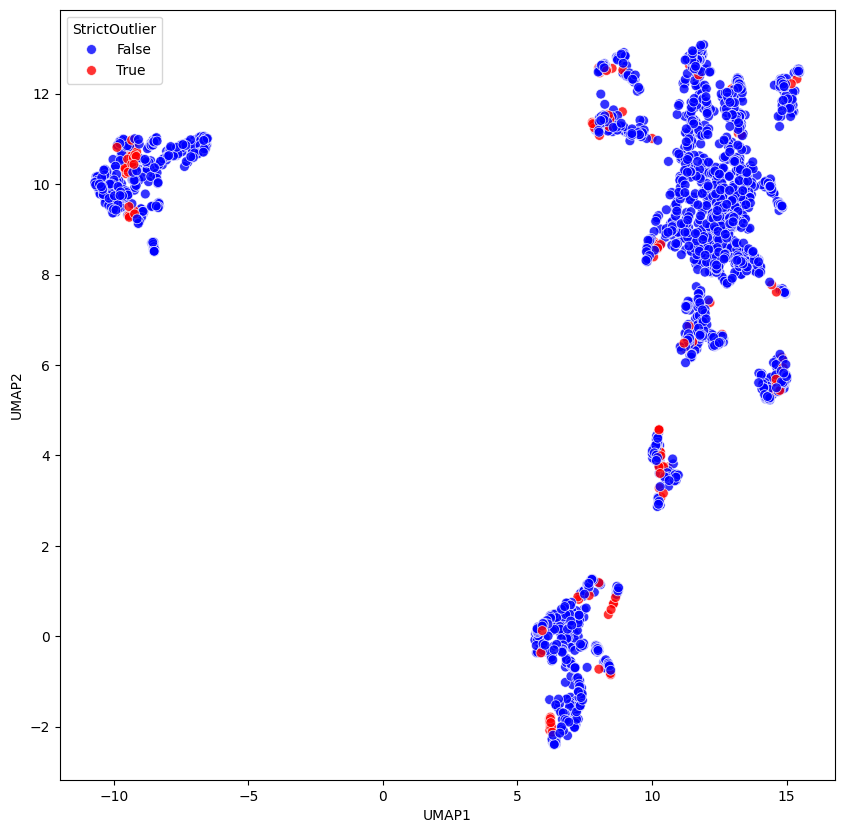

In [10]:

def report_outlier_results(umap_hdbscan_df, dataset_name):
    strict_outliers = umap_hdbscan_df['StrictOutlier'].sum()
    print(f"Strict outliers detected in {dataset_name}: {strict_outliers}")

    # Join umap on target to get class labels
    umap_hdbscan_df = umap_hdbscan_df.join(y_b_all, how='left')

    # Print each item where strict outlier is True including class
    strict_outliers = umap_hdbscan_df[umap_hdbscan_df['StrictOutlier'] == True][['class', 'OutlierScore', 'StrictOutlier']]
    # print(strict_outliers)

    # print class counts of the outliers above
    print(strict_outliers['class'].value_counts())

    # Now the above but only the hypodiploid cases
    # print("Hypodiploid strict outliers:")
    # print(umap_hdbscan_df[(umap_hdbscan_df['StrictOutlier'] == True) & (umap_hdbscan_df['class'].str.contains('hypodiploid'))][['class', 'OutlierScore', 'StrictOutlier']])

    # Now only ETV6::RUNX1 cases
    print("ETV6::RUNX1 strict outliers:")
    print(umap_hdbscan_df[(umap_hdbscan_df['StrictOutlier'] == True) & (umap_hdbscan_df['class'].str.contains('ETV6::RUNX1'))][['class', 'OutlierScore', 'StrictOutlier']])

    # Plot UMAP with outliers highlighted
    plt.figure(figsize=(10,10))
    sns.scatterplot(x='UMAP1',
                    y='UMAP2',
                    hue='StrictOutlier',
                    data=umap_hdbscan_df,
                    palette={True: 'red', False: 'blue'},
                    s=50,
                    alpha=0.8)

    print("\n")

report_outlier_results(umap_hdbscan_df, "B-ALL")

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Strict outliers detected in AML: 18
Series([], Name: count, dtype: int64)
ETV6::RUNX1 strict outliers:
Empty DataFrame
Columns: [class, OutlierScore, StrictOutlier]
Index: []




/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


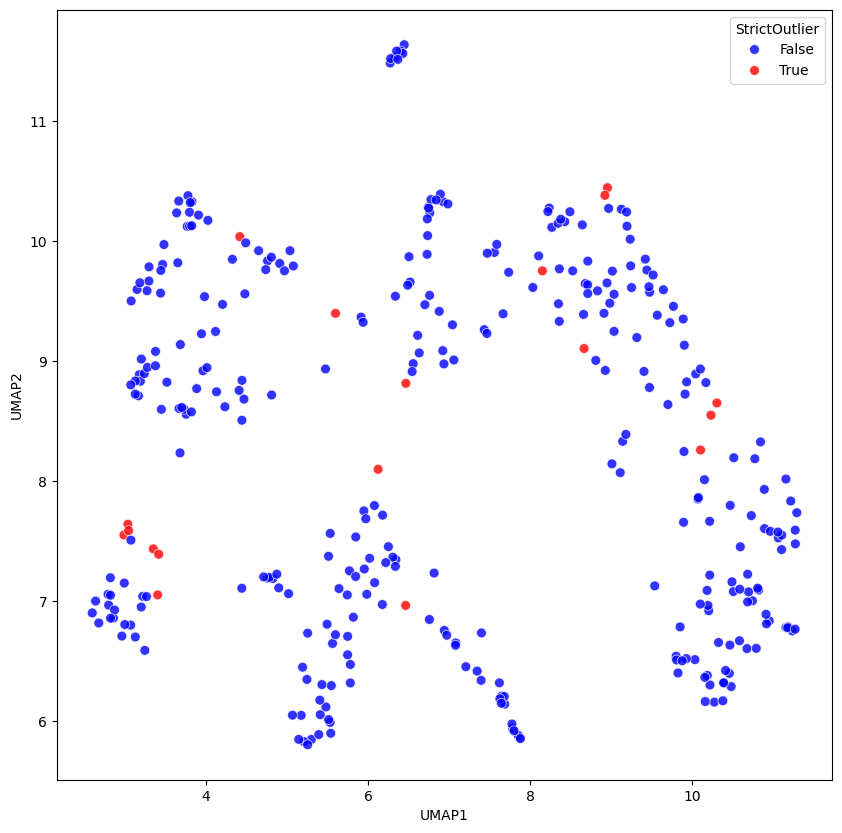

In [11]:
umap_hdbscan_df = umap_hdbscan_with_text(X_aml,
                                         y_aml,
                                         outlier_threshold_percentile=OUTLIER_THRESHOLD_PERCENTILE)
report_outlier_results(umap_hdbscan_df, "AML")